# EcoPulse AI — Phase 3

## 1. Project Introduction

**Project:** EcoPulse AI — Intelligent Energy Consumption Monitoring, Forecasting
and Anomaly Detection System

**Tagline:** *Understand Energy. Predict Tomorrow. Optimise Smarter.*

This notebook is the Phase 3 deliverable for data cleaning, transformation and
validation. It works from the immutable UCI Individual Household Electric Power
Consumption dataset and from the production modules in `data-engineering/src/`.
Every decision below is supported by measured counts from the actual data.

The notebook does **not** train a model, forecast consumption, perform anomaly
detection, build dashboards, use cloud services, or start Phase 4. It also does
not modify `data/raw/household_power_consumption.txt`.

Phase 2 remains the evidence base for the raw-data profile. Phase 3 applies a
deliberately narrow cleaning policy and records every removed, retained, and
interpolated value.

## 2. Objectives

1. Parse `Date` and `Time` into one validated timestamp and report invalid values.
2. Convert the seven measurement columns to numeric, mapping `?` to `NaN`.
3. Quantify missing cells, fully missing rows and consecutive missing runs.
4. Detect duplicate records and duplicate timestamps.
5. Interpolate only internal gaps of at most five consecutive minutes.
6. Keep longer gaps unresolved, never zero-fill, and remove unresolved rows only
   from the final modelling dataset.
7. Measure IQR and physical-domain outliers without deleting genuine consumption
   peaks.
8. Build calendar features and
   `energy_consumption_kwh = Global_active_power / 60`.
9. Build gap-aware hourly, daily and monthly aggregates with expected, valid and
   imputed counts.
10. Validate the outputs and summarise the measured cleaning and transformation
    results.

## 3. Import Libraries

Pandas and NumPy perform the data work, Matplotlib and Seaborn produce the
figures, and the standard library keeps paths and production-module loading
independent of the working directory.

In [1]:
from __future__ import annotations

import gc
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "figure.dpi": 110,
        "axes.titleweight": "bold",
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

## 4. Configuration and Paths

The repository root is discovered by walking up from the notebook's working
directory. The same numbered production scripts used by the ETL pipeline are
loaded as modules, so the notebook cannot silently diverge from the pipeline
logic. Generated figures go to `reports/data-engineering/figures/`.

In [2]:
def find_project_root() -> Path:
    """Find the repository root from the notebook or Jupyter working directory."""
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "household_power_consumption.txt").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/raw/household_power_consumption.txt. "
        "Open this notebook from inside the EcoPulse-AI repository."
    )


def load_module(module_name: str, path: Path):
    """Load a numbered production script as an importable module."""
    spec = importlib.util.spec_from_file_location(module_name, path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Could not load module {module_name} from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "data-engineering" / "src"
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "household_power_consumption.txt"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "data-engineering"
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MINUTE_PATH = PROCESSED_DIR / "household_power_cleaned.parquet"
HOURLY_PATH = PROCESSED_DIR / "household_power_hourly.parquet"
DAILY_PATH = PROCESSED_DIR / "household_power_daily.parquet"
MONTHLY_PATH = PROCESSED_DIR / "household_power_monthly.parquet"

cleaner = load_module("phase3_notebook_cleaning", SRC_DIR / "02_clean_dataset.py")
transformer = load_module(
    "phase3_notebook_transformation", SRC_DIR / "03_transform_dataset.py"
)
pipeline = load_module("phase3_notebook_pipeline", SRC_DIR / "04_run_etl_pipeline.py")

print(f"Project root:  {PROJECT_ROOT}")
print(f"Raw dataset:   {RAW_PATH}")
print(f"Figure folder: {FIGURE_DIR.relative_to(PROJECT_ROOT).as_posix()}")
print(f"pandas {pd.__version__} | NumPy {np.__version__}")

Project root:  D:\ai\EcoPulse-AI
Raw dataset:   D:\ai\EcoPulse-AI\data\raw\household_power_consumption.txt
Figure folder: reports/data-engineering/figures
pandas 2.3.3 | NumPy 2.5.5


## 5. Load Raw Dataset

The raw file is read-only. The semicolon delimiter is used, `?` is mapped to
`NaN`, and the seven measurement columns are coerced to numeric. The loader also
combines `Date` and `Time` into one parsed timestamp. No row is dropped here.

In [3]:
raw_sha256 = cleaner.sha256sum(RAW_PATH)
print(f"Raw SHA-256:          {raw_sha256}")
print(f"Expected SHA-256:     {cleaner.EXPECTED_RAW_SHA256}")
print(f"Checksum match:       {raw_sha256 == cleaner.EXPECTED_RAW_SHA256}")
print(f"Raw file size:        {cleaner.format_bytes(RAW_PATH.stat().st_size)}")

raw_df = cleaner.load_raw_dataset(RAW_PATH)
print(f"Loaded rows:          {len(raw_df):,}")
print(f"Loaded columns:       {raw_df.shape[1]:,}")
display(raw_df.head(3))

Raw SHA-256:          4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7
Expected SHA-256:     4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7
Checksum match:       True
Raw file size:        126.80 MB


Loaded rows:          2,075,259
Loaded columns:       10


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,timestamp
0,16/12/2006,17:24:00,4.2160,0.4180,234.8400,18.4000,0.0000,1.0000,17.0000,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.3600,0.4360,233.6300,23.0000,0.0000,1.0000,16.0000,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.3740,0.4980,233.2900,23.0000,0.0000,2.0000,17.0000,2006-12-16 17:26:00


## 6. Timestamp Parsing and Validation

The timestamp format is `%d/%m/%Y %H:%M:%S`. A valid minute grid is essential
for gap detection and for honest aggregation. Timestamps remain naive local
civil time because the source has no UTC offset; this is recorded as a
validation warning rather than silently shifting the data.

In [4]:
timestamp = raw_df["timestamp"]
invalid_timestamps = int(timestamp.isna().sum())
duplicate_timestamps = int(timestamp.duplicated(keep="first").sum())
duplicate_groups = int(
    raw_df.loc[timestamp.duplicated(keep=False), "timestamp"].nunique()
)
intervals = timestamp.diff().dropna()

timestamp_summary = pd.DataFrame(
    [
        {"Check": "Earliest timestamp", "Value": f"{timestamp.min():%Y-%m-%d %H:%M:%S}"},
        {"Check": "Latest timestamp", "Value": f"{timestamp.max():%Y-%m-%d %H:%M:%S}"},
        {"Check": "Invalid timestamps", "Value": f"{invalid_timestamps:,}"},
        {"Check": "Duplicate timestamp rows", "Value": f"{duplicate_timestamps:,}"},
        {"Check": "Duplicate timestamp groups", "Value": f"{duplicate_groups:,}"},
        {"Check": "Unique timestamp values", "Value": f"{timestamp.nunique():,}"},
        {
            "Check": "Most common interval",
            "Value": f"{intervals.value_counts().index[0]} "
            f"({int(intervals.value_counts().iloc[0]):,} times)",
        },
    ]
)
display(timestamp_summary)

assert invalid_timestamps == 0, "Invalid timestamps require explicit handling."
print("Timestamp parsing passed: no invalid values and a complete one-minute grid.")

,Check,Value
0,Earliest timestamp,2006-12-16 17:24:00
1,Latest timestamp,2010-11-26 21:02:00
2,Invalid timestamps,0
3,Duplicate timestamp rows,0
4,Duplicate timestamp groups,0
5,Unique timestamp values,"2,075,259"
6,Most common interval,"0 days 00:01:00 (2,075,258 times)"


Timestamp parsing passed: no invalid values and a complete one-minute grid.


## 7. Missing Values Analysis

Phase 2 showed that missingness is block-wise: every affected timestamp is
missing all seven measurements. This section confirms that structure and
quantifies the missing cells before any treatment. Missing readings are unknown
consumption, not measured zeros.

,Column,Missing Values,Missing %,Non-Missing Values
0,Global_active_power,25979,1.2518,2049280
1,Global_reactive_power,25979,1.2518,2049280
2,Voltage,25979,1.2518,2049280
3,Global_intensity,25979,1.2518,2049280
4,Sub_metering_1,25979,1.2518,2049280
5,Sub_metering_2,25979,1.2518,2049280
6,Sub_metering_3,25979,1.2518,2049280


Missing measurement cells:       181,853
Total measurement cells:         14,526,813
Rows with any missing value:     25,979
Fully missing rows:              25,979
Partially missing rows:          0


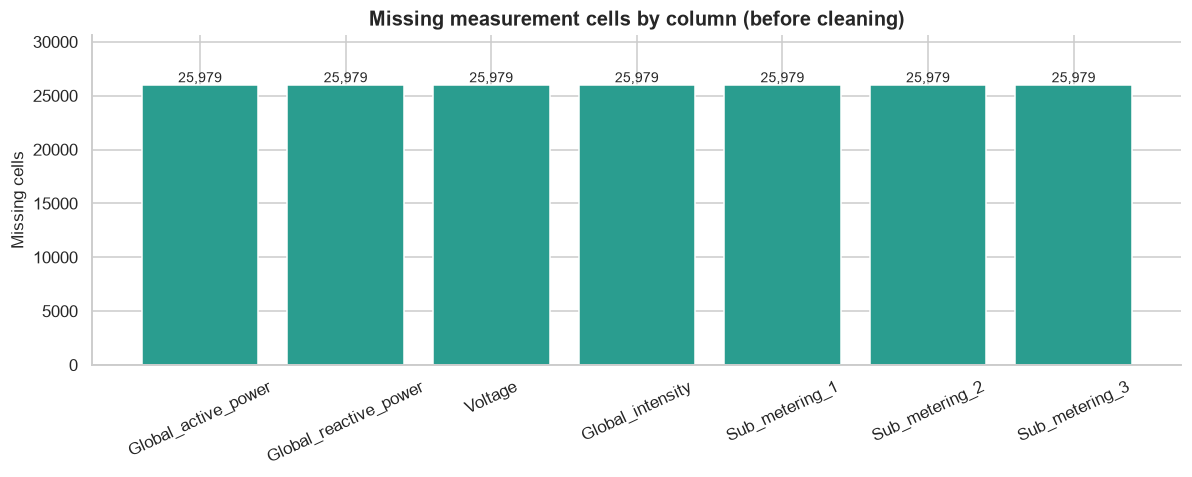

In [5]:
missing_by_column = raw_df[cleaner.NUMERIC_COLUMNS].isna().sum()
total_cells = len(raw_df) * len(cleaner.NUMERIC_COLUMNS)
missing_table = pd.DataFrame(
    {
        "Column": cleaner.NUMERIC_COLUMNS,
        "Missing Values": [int(missing_by_column[column]) for column in cleaner.NUMERIC_COLUMNS],
    }
)
missing_table["Missing %"] = missing_table["Missing Values"] / len(raw_df) * 100
missing_table["Non-Missing Values"] = len(raw_df) - missing_table["Missing Values"]

fully_missing_mask = raw_df[cleaner.NUMERIC_COLUMNS].isna().all(axis=1)
any_missing_mask = raw_df[cleaner.NUMERIC_COLUMNS].isna().any(axis=1)
partial_missing_rows = int(any_missing_mask.sum() - fully_missing_mask.sum())

display(missing_table)
print(f"Missing measurement cells:       {int(missing_by_column.sum()):,}")
print(f"Total measurement cells:         {total_cells:,}")
print(f"Rows with any missing value:     {int(any_missing_mask.sum()):,}")
print(f"Fully missing rows:              {int(fully_missing_mask.sum()):,}")
print(f"Partially missing rows:          {partial_missing_rows:,}")

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(
    missing_table["Column"],
    missing_table["Missing Values"],
    color="#2a9d8f",
)
ax.set_title("Missing measurement cells by column (before cleaning)")
ax.set_ylabel("Missing cells")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=25)
for bar, value in zip(bars, missing_table["Missing Values"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=9,
    )
ax.set_ylim(0, missing_table["Missing Values"].max() * 1.18)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_missing_values_by_column.png", bbox_inches="tight")
plt.show()

assert partial_missing_rows == 0, "Partial rows would need a separate policy."

## 8. Duplicate Records Analysis

Duplicate complete rows and duplicate timestamps are measured separately. If
duplicates existed, the deterministic policy would keep the first chronological
occurrence. In the actual dataset both counts are zero, so no row is removed for
duplication.

In [6]:
complete_duplicates = int(raw_df.duplicated().sum())
duplicate_timestamp_rows = int(raw_df["timestamp"].duplicated(keep="first").sum())
duplicate_timestamp_groups = int(
    raw_df.loc[raw_df["timestamp"].duplicated(keep=False), "timestamp"].nunique()
)
duplicate_table = pd.DataFrame(
    [
        {"Check": "Duplicate complete rows", "Count": complete_duplicates},
        {"Check": "Duplicate timestamp rows", "Count": duplicate_timestamp_rows},
        {"Check": "Duplicate timestamp groups", "Count": duplicate_timestamp_groups},
        {"Check": "Rows removed for duplicates", "Count": 0},
    ]
)
display(duplicate_table)
print("Duplicate policy: keep the first chronological occurrence.")
print("Actual dataset result: no duplicate record or timestamp was found.")

,Check,Count
0,Duplicate complete rows,0
1,Duplicate timestamp rows,0
2,Duplicate timestamp groups,0
3,Rows removed for duplicates,0


Duplicate policy: keep the first chronological occurrence.
Actual dataset result: no duplicate record or timestamp was found.


## 9. Missing-Interval (Gap) Analysis

A gap is a consecutive run of fully missing rows. The distinction between short
and long gaps drives the cleaning policy: only short internal gaps are eligible
for interpolation. Run lengths are measured on the complete timestamp grid using
the same helper as the production cleaning module.

,Bucket,Runs,Rows
0,1 minute,38,38
1,2 minutes,14,28
2,3-5 minutes,3,10
3,6-10 minutes,1,6
4,11-30 minutes,2,45
5,31-60 minutes,4,161
6,61 minutes-1 day,3,1044
7,More than 1 day,6,24647


Total missing runs:            71
Short runs (<= 5 minutes):     55 runs, 76 rows
Long runs (> 5 minutes):       16 runs, 25,903 rows


,Start,End,Rows,Duration (minutes)
0,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,7226
1,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,5237
2,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,3723
3,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,3305
4,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,3129
5,2010-03-20 03:52:00,2010-03-21 13:38:00,2027,2027
6,2009-08-13 05:00:00,2009-08-13 19:50:00,891,891
7,2007-07-15 16:49:00,2007-07-15 18:11:00,83,83
8,2008-12-10 10:48:00,2008-12-10 11:57:00,70,70
9,2007-07-15 18:21:00,2007-07-15 19:07:00,47,47


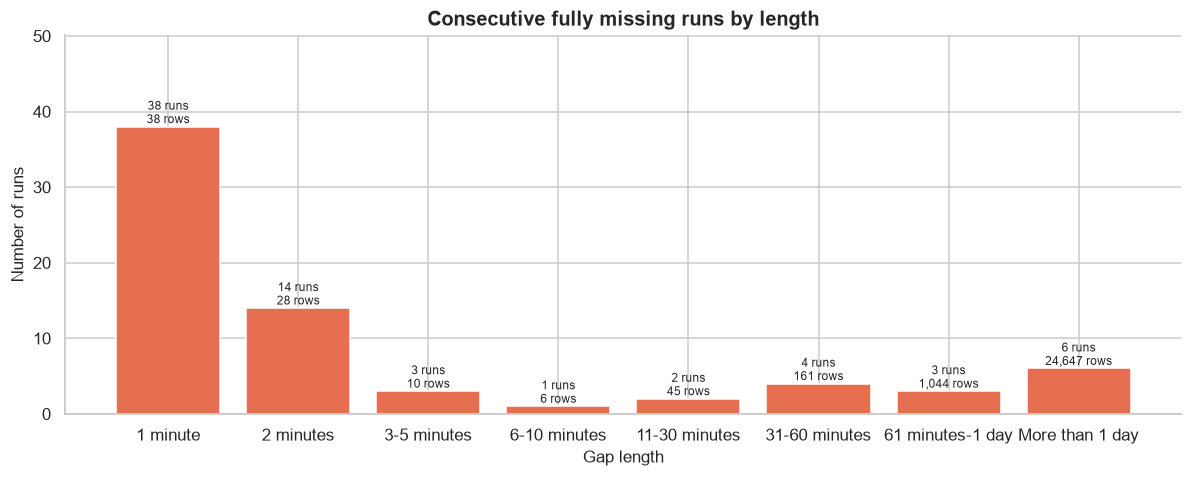

In [7]:
runs = cleaner._find_missing_runs(raw_df["timestamp"], fully_missing_mask)
run_lengths = pd.Series([run.rows for run in runs], name="Rows")
short_runs = [run for run in runs if run.is_short]
long_runs = [run for run in runs if not run.is_short]

gap_buckets = pd.DataFrame(cleaner._gap_bucket_table(runs))
display(gap_buckets)

print(f"Total missing runs:            {len(runs):,}")
print(f"Short runs (<= 5 minutes):     {len(short_runs):,} runs, "
      f"{sum(run.rows for run in short_runs):,} rows")
print(f"Long runs (> 5 minutes):       {len(long_runs):,} runs, "
      f"{sum(run.rows for run in long_runs):,} rows")

long_gap_table = pd.DataFrame(
    [
        {
            "Start": run.start_timestamp,
            "End": run.end_timestamp,
            "Rows": run.rows,
            "Duration (minutes)": run.duration_minutes,
        }
        for run in sorted(long_runs, key=lambda item: item.rows, reverse=True)[:10]
    ]
)
display(long_gap_table)

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(gap_buckets["Bucket"], gap_buckets["Runs"], color="#e76f51")
ax.set_title("Consecutive fully missing runs by length")
ax.set_ylabel("Number of runs")
ax.set_xlabel("Gap length")
for bar, runs_count, rows_count in zip(
    bars, gap_buckets["Runs"], gap_buckets["Rows"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{runs_count} runs\n{rows_count:,} rows",
        ha="center",
        va="bottom",
        fontsize=8,
    )
ax.set_ylim(0, max(gap_buckets["Runs"].max() * 1.32, 1))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_missing_run_distribution.png", bbox_inches="tight")
plt.show()

assert len(short_runs) == 55 and sum(run.rows for run in short_runs) == 76
assert len(long_runs) == 16 and sum(run.rows for run in long_runs) == 25_903

## 10. Short-Gap Interpolation

Only gaps of one to five consecutive minutes are interpolated, using time-based
linear interpolation on the one-minute index and all seven measurement columns.
The production cleaning function is called directly so the notebook and pipeline
share exactly the same code path. Longer gaps are left unresolved.

`is_imputed` marks every row that received an interpolated value.

,Metric,Value
0,Eligible short runs,55
1,Imputed rows,76
2,Imputed cells,532
3,Imputed energy (kWh),2.422850
4,Maximum gap (minutes),5
5,Safety guard,PASSED


,Column,Imputed cells
0,Global_active_power,76
1,Global_reactive_power,76
2,Voltage,76
3,Global_intensity,76
4,Sub_metering_1,76
5,Sub_metering_2,76
6,Sub_metering_3,76


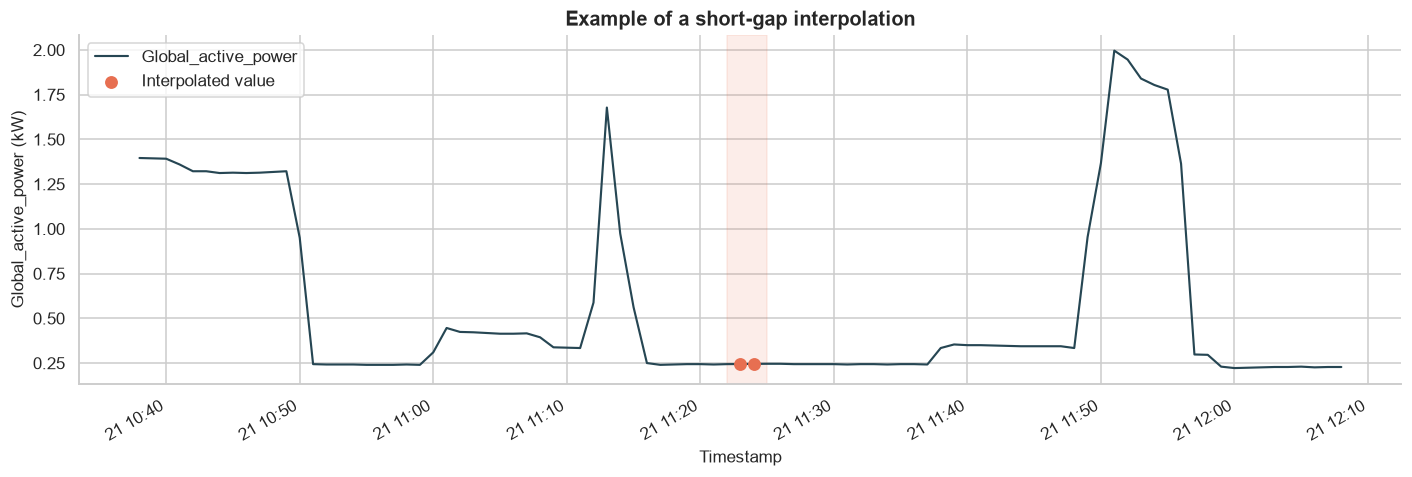

In [8]:
cleaned, cleaning_stats = cleaner.clean_dataset(raw_df)
del raw_df
_ = gc.collect()

interpolation_summary = pd.DataFrame(
    [
        {"Metric": "Eligible short runs", "Value": f"{cleaning_stats.interpolated_gap_runs:,}"},
        {"Metric": "Imputed rows", "Value": f"{cleaning_stats.interpolated_rows:,}"},
        {"Metric": "Imputed cells", "Value": f"{cleaning_stats.interpolated_cells:,}"},
        {"Metric": "Imputed energy (kWh)", "Value": f"{cleaning_stats.imputed_energy_kwh:,.6f}"},
        {"Metric": "Maximum gap (minutes)", "Value": f"{cleaning_stats.interpolation_limit_minutes}"},
        {"Metric": "Safety guard", "Value": "PASSED" if cleaning_stats.interpolation_guard_passed else "FAILED"},
    ]
)
display(interpolation_summary)
display(
    pd.DataFrame(
        [
            {"Column": column, "Imputed cells": count}
            for column, count in cleaning_stats.imputed_by_column.items()
        ]
    )
)

first_imputed = cleaned.loc[cleaned["is_imputed"], "timestamp"].min()
window = cleaned.loc[
    cleaned["timestamp"].between(
        first_imputed - pd.DateOffset(minutes=45),
        first_imputed + pd.DateOffset(minutes=45),
    )
]
imputed_window = window.loc[window["is_imputed"]]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(
    window["timestamp"],
    window["Global_active_power"],
    color="#264653",
    linewidth=1.4,
    label="Global_active_power",
)
ax.scatter(
    imputed_window["timestamp"],
    imputed_window["Global_active_power"],
    color="#e76f51",
    s=55,
    zorder=3,
    label="Interpolated value",
)
ax.axvspan(
    first_imputed - pd.DateOffset(minutes=1),
    first_imputed + pd.DateOffset(minutes=2),
    color="#e76f51",
    alpha=0.12,
)
ax.set_title("Example of a short-gap interpolation")
ax.set_ylabel("Global_active_power (kW)")
ax.set_xlabel("Timestamp")
ax.legend(loc="upper left")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_short_gap_interpolation.png", bbox_inches="tight")
plt.show()

assert cleaning_stats.interpolated_rows == 76
assert cleaning_stats.interpolated_cells == 532
assert cleaning_stats.interpolation_guard_passed

## 11. Unresolved Gaps and Removed Rows

Long gaps are not interpolated, zero-filled, or otherwise fabricated. Their rows
remain unresolved and are removed only from the final modelling dataset. The
removal count is reported explicitly so that the gap between the raw grid and the
modelling data can never be mistaken for complete coverage.

,Stage,Rows
0,Original raw rows,2075259
1,Fully missing rows (before treatment),25979
2,Short-gap imputed rows (retained),76
3,Unresolved rows removed for modelling,25903
4,Final modelling rows,2049356


Final missing measurement cells: 0
Expected one-minute slots:       2,075,259
Timestamp row coverage:          100.0000% (raw slots present)
Final modelling coverage:        98.7518% (valid rows)
Removed rows are excluded from modelling; they were not filled with zero.


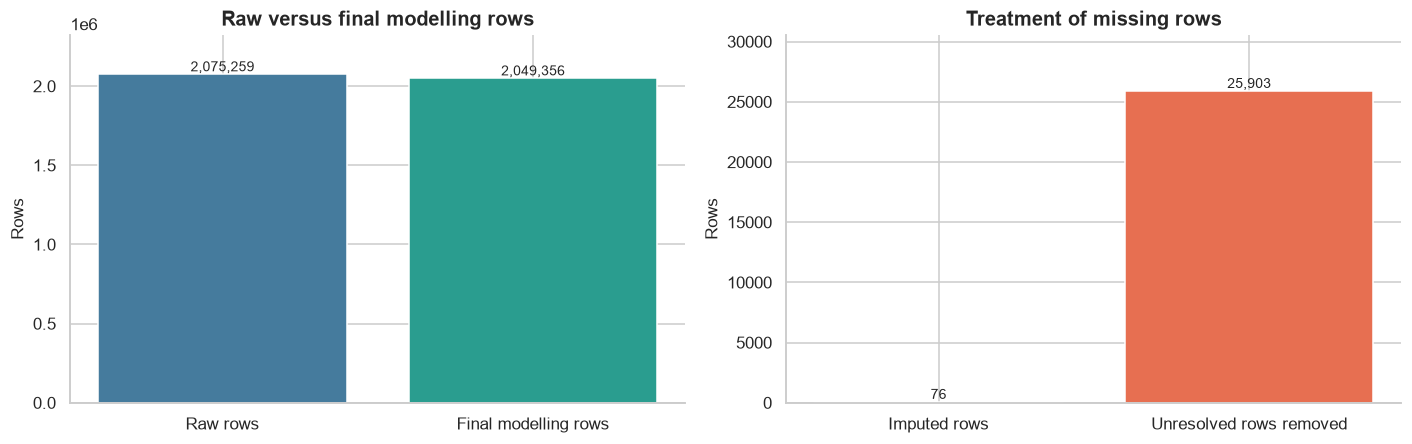

In [9]:
continuity = pd.DataFrame(
    [
        {"Stage": "Original raw rows", "Rows": cleaning_stats.raw_rows},
        {"Stage": "Fully missing rows (before treatment)", "Rows": cleaning_stats.original_fully_missing_rows},
        {"Stage": "Short-gap imputed rows (retained)", "Rows": cleaning_stats.interpolated_rows},
        {"Stage": "Unresolved rows removed for modelling", "Rows": cleaning_stats.removed_rows},
        {"Stage": "Final modelling rows", "Rows": cleaning_stats.final_rows},
    ]
)
display(continuity)
print(f"Final missing measurement cells: {cleaning_stats.final_missing_cells:,}")
print(f"Expected one-minute slots:       {cleaning_stats.expected_grid_slots:,}")
print(
    f"Timestamp row coverage:          {cleaning_stats.grid_coverage_percent:.4f}% "
    "(raw slots present)"
)
print(
    f"Final modelling coverage:        "
    f"{cleaning_stats.final_rows / cleaning_stats.expected_grid_slots * 100:.4f}% "
    "(valid rows)"
)
print("Removed rows are excluded from modelling; they were not filled with zero.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(
    ["Raw rows", "Final modelling rows"],
    [cleaning_stats.raw_rows, cleaning_stats.final_rows],
    color=["#457b9d", "#2a9d8f"],
)
axes[0].set_title("Raw versus final modelling rows")
axes[0].set_ylabel("Rows")
for position, value in enumerate([cleaning_stats.raw_rows, cleaning_stats.final_rows]):
    axes[0].text(position, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, cleaning_stats.raw_rows * 1.12)

axes[1].bar(
    ["Imputed rows", "Unresolved rows removed"],
    [cleaning_stats.interpolated_rows, cleaning_stats.removed_rows],
    color=["#e9c46a", "#e76f51"],
)
axes[1].set_title("Treatment of missing rows")
axes[1].set_ylabel("Rows")
for position, value in enumerate([cleaning_stats.interpolated_rows, cleaning_stats.removed_rows]):
    axes[1].text(position, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, cleaning_stats.removed_rows * 1.18)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_record_continuity.png", bbox_inches="tight")
plt.show()

assert cleaning_stats.removed_rows == 25_903
assert cleaning_stats.final_rows == 2_049_356
assert cleaning_stats.final_missing_cells == 0

## 12. Outlier Analysis

IQR fences (`Q1 - 1.5*IQR`, `Q3 + 1.5*IQR`) identify unusual measurement cells.
Outliers are documented, not deleted or capped: high whole-house readings are
genuine consumption peaks, and `Sub_metering_1` has a zero IQR because most
minutes are idle. Removing these values would distort real behaviour.

,Column,Q1,Q3,IQR,Lower bound,Upper bound,Outliers,Outlier %,Extreme outliers,Minimum,Maximum
0,Global_active_power,0.3080,1.5280,1.2200,-1.5220,3.3580,94919,4.6317,14379,0.0760,11.1220
1,Global_reactive_power,0.0480,0.1940,0.1460,-0.1710,0.4130,40425,1.9726,3899,0.0000,1.3900
2,Voltage,238.9900,242.8900,3.9000,233.1400,248.7400,51068,2.4919,898,223.2000,254.1500
3,Global_intensity,1.4000,6.4000,5.0000,-6.1000,13.9000,100973,4.9271,16469,0.2000,48.4000
4,Sub_metering_1,0.0000,0.0000,0.0000,0.0000,0.0000,169118,8.2523,169118,0.0000,88.0000
5,Sub_metering_2,0.0000,1.0000,1.0000,-1.5000,2.5000,77166,3.7654,64237,0.0000,80.0000
6,Sub_metering_3,0.0000,17.0000,17.0000,-25.5000,42.5000,0,0.0000,0,0.0000,31.0000


IQR outlier cells identified and retained: 533,669
Outlier cells removed:                     0


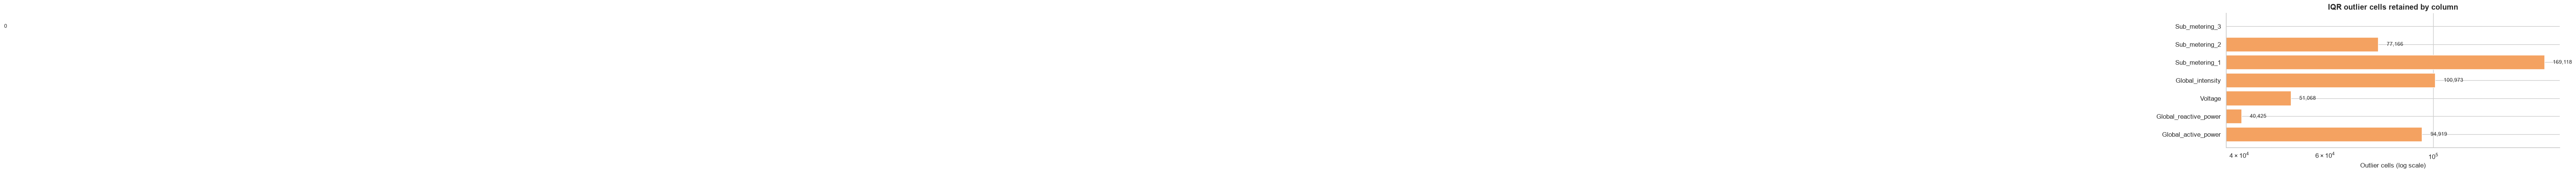

In [10]:
outlier_table = pd.DataFrame(cleaning_stats.outlier_table)
display(outlier_table.round(4))
retained_outlier_cells = int(outlier_table["Outliers"].sum())
print(f"IQR outlier cells identified and retained: {retained_outlier_cells:,}")
print(f"Outlier cells removed:                     {cleaning_stats.outliers_removed:,}")

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.barh(
    outlier_table["Column"],
    outlier_table["Outliers"],
    color="#f4a261",
)
ax.set_xscale("log")
ax.set_title("IQR outlier cells retained by column")
ax.set_xlabel("Outlier cells (log scale)")
for bar, value in zip(bars, outlier_table["Outliers"]):
    ax.text(
        max(float(value), 1.0) * 1.04,
        bar.get_y() + bar.get_height() / 2,
        f"{int(value):,}",
        va="center",
        fontsize=9,
    )
fig.subplots_adjust(left=0.24, right=0.97, top=0.88, bottom=0.16)
fig.savefig(FIGURE_DIR / "phase3_outlier_summary.png", bbox_inches="tight")
plt.show()

assert cleaning_stats.outliers_removed == 0

## 13. Domain Validation

Broad physical ranges are checked without enforcing them as deletion rules. One
known source inconsistency is important: in some minutes the three sub-metered
circuits sum to more energy than the whole-house meter. These values are retained
and reported rather than "corrected" with invented numbers.

,Check,Violations,Status,Detail
0,Global_active_power is non-negative,0,PASS,A negative whole-house active power reading is...
1,Global_reactive_power is non-negative,0,PASS,A negative reactive power reading is physicall...
2,Voltage is in the plausible range 180-260 V,0,PASS,Broad French low-voltage plausibility band; no...
3,Global_intensity is in the plausible range 0-1...,0,PASS,Broad household current plausibility band; not...
4,Global_active_power is at most 20 kW,0,PASS,A broad upper bound for a single household; no...
5,Sub-metering values are non-negative,0,PASS,Sub-metering is reported in Wh per minute and ...
6,Sub-metered energy does not exceed whole-house...,1050,REVIEW,Known UCI measurement inconsistency; retained ...


Sub-metering above whole-house energy: 1,050 minutes (0.0512%).


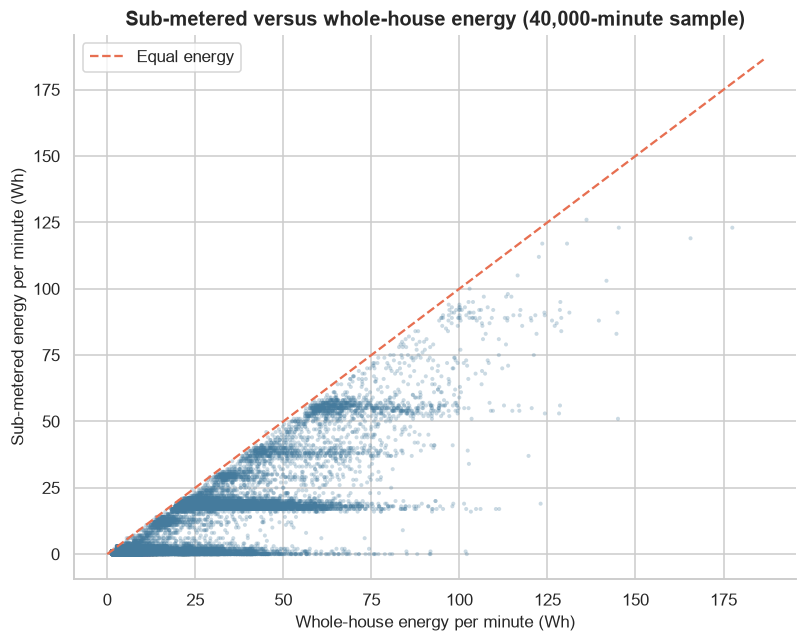

In [11]:
domain_table = pd.DataFrame(cleaning_stats.domain_checks)
display(domain_table)

print(
    f"Sub-metering above whole-house energy: "
    f"{cleaning_stats.submetering_violation_rows:,} minutes "
    f"({cleaning_stats.submetering_violation_percent:.4f}%)."
)

sample = cleaned.sample(n=min(40_000, len(cleaned)), random_state=42)
whole_house_wh = sample["Global_active_power"] * 1000 / 60
submetered_wh = sample[cleaner.SUB_METERING_COLUMNS].sum(axis=1)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(
    whole_house_wh,
    submetered_wh,
    s=7,
    alpha=0.28,
    color="#457b9d",
    edgecolors="none",
)
limit = float(max(whole_house_wh.max(), submetered_wh.max())) * 1.05
ax.plot(
    [0, limit],
    [0, limit],
    color="#e76f51",
    linestyle="--",
    linewidth=1.5,
    label="Equal energy",
)
ax.set_xlabel("Whole-house energy per minute (Wh)")
ax.set_ylabel("Sub-metered energy per minute (Wh)")
ax.set_title("Sub-metered versus whole-house energy (40,000-minute sample)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_submetering_check.png", bbox_inches="tight")
plt.show()

assert cleaning_stats.submetering_violation_rows > 0

## 14. Load Processed Datasets and Verify Schema

The ETL pipeline has already written the four Phase 3 Parquet files. This section
reads them back independently and checks their shape, missing cells, timestamp
uniqueness and schema. The minute file is the final modelling dataset with
calendar features and energy already applied by the transformation stage.

In [12]:
dataset_paths = {
    "Minute": MINUTE_PATH,
    "Hourly": HOURLY_PATH,
    "Daily": DAILY_PATH,
    "Monthly": MONTHLY_PATH,
}
missing_outputs = [str(path.name) for path in dataset_paths.values() if not path.exists()]
if missing_outputs:
    raise FileNotFoundError(
        "Missing processed outputs: "
        + ", ".join(missing_outputs)
        + ". Run data-engineering/src/04_run_etl_pipeline.py first."
    )

summary_rows = []
minute_schema = None
minute_preview = None
for name, path in dataset_paths.items():
    frame = pd.read_parquet(path)
    time_column = "timestamp" if name == "Minute" else "period_start"
    summary_rows.append(
        {
            "Dataset": name,
            "Rows": len(frame),
            "Columns": frame.shape[1],
            "Missing cells": int(frame.isna().sum().sum()),
            "Duplicate timestamps": int(frame[time_column].duplicated().sum()),
            "Size": cleaner.format_bytes(path.stat().st_size),
        }
    )
    if name == "Minute":
        minute_schema = frame.dtypes.rename("dtype").to_frame()
        minute_preview = frame.head(3)
        assert not frame["timestamp"].duplicated().any()
        assert frame["timestamp"].is_monotonic_increasing
    del frame

display(pd.DataFrame(summary_rows))
display(minute_schema)
display(minute_preview)
print("All four Parquet outputs were read back successfully.")

,Dataset,Rows,Columns,Missing cells,Duplicate timestamps,Size
0,Minute,2049356,18,0,0,26.95 MB
1,Hourly,34589,20,5894,0,1.54 MB
2,Daily,1442,20,126,0,150.40 KB
3,Monthly,48,20,0,0,20.00 KB


,dtype
timestamp,datetime64[ns]
year,int16
month,int8
day,int8
hour,int8
minute,int8
day_of_week,int8
day_name,object
is_weekend,bool
Global_active_power,float64


,timestamp,year,month,day,hour,minute,day_of_week,day_name,is_weekend,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,energy_consumption_kwh,is_imputed
0,2006-12-16 17:24:00,2006,12,16,17,24,5,Saturday,True,4.2160,0.4180,234.8400,18.4000,0.0000,1.0000,17.0000,0.0703,False
1,2006-12-16 17:25:00,2006,12,16,17,25,5,Saturday,True,5.3600,0.4360,233.6300,23.0000,0.0000,1.0000,16.0000,0.0893,False
2,2006-12-16 17:26:00,2006,12,16,17,26,5,Saturday,True,5.3740,0.4980,233.2900,23.0000,0.0000,2.0000,17.0000,0.0896,False


All four Parquet outputs were read back successfully.


## 15. Datetime Feature Engineering

Calendar features are derived only from the timestamp itself: year, month, day,
hour, minute, day of week, day name and weekend flag. No lag, rolling window,
future observation, target encoding or other leakage-prone feature is created in
Phase 3.

In [13]:
feature_frame = transformer.add_datetime_features(cleaned.copy())
feature_frame = transformer.add_energy_feature(feature_frame)

feature_preview = feature_frame[
    ["timestamp", *transformer.DATETIME_COLUMNS, transformer.ENERGY_COLUMN]
].head(5)
display(feature_preview)

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_counts = (
    feature_frame["day_name"]
    .value_counts()
    .reindex(day_order)
    .rename("Minutes")
    .to_frame()
)
display(day_counts)
print(f"New calendar features: {', '.join(transformer.DATETIME_COLUMNS)}")
print(f"Weekend rows:          {int(feature_frame['is_weekend'].sum()):,}")
print("Every calendar feature is a direct transformation of the timestamp.")

del feature_frame
_ = gc.collect()

,timestamp,year,month,day,hour,minute,day_of_week,day_name,is_weekend,energy_consumption_kwh
0,2006-12-16 17:24:00,2006,12,16,17,24,5,Saturday,True,0.0703
1,2006-12-16 17:25:00,2006,12,16,17,25,5,Saturday,True,0.0893
2,2006-12-16 17:26:00,2006,12,16,17,26,5,Saturday,True,0.0896
3,2006-12-16 17:27:00,2006,12,16,17,27,5,Saturday,True,0.0898
4,2006-12-16 17:28:00,2006,12,16,17,28,5,Saturday,True,0.0611


,Minutes
day_name,
Monday,293875
Tuesday,294738
Wednesday,293669
Thursday,293167
Friday,295023
Saturday,288839
Sunday,290045


New calendar features: year, month, day, hour, minute, day_of_week, day_name, is_weekend
Weekend rows:          578,884
Every calendar feature is a direct transformation of the timestamp.


## 16. Energy Consumption Calculation

`Global_active_power` is a one-minute average in kW. Dividing by 60 gives the
energy contribution of that valid minute in kWh:

```
energy_consumption_kwh = Global_active_power / 60
```

Missing readings remain `NaN`; they are never replaced by zero. The transformation
is run on the cleaned data to produce the final minute dataset and the three
aggregates used below.

,Metric,Value
0,Measured valid-reading energy (kWh),"37,283.747700"
1,Imputed short-gap energy (kWh),2.422850
2,Total energy including imputed (kWh),"37,286.170550"
3,Phase 2 valid-reading total (kWh),"37,283.747700"
4,Sub-metered energy (kWh),"18,196.410000"
5,Sub-metered share of total,48.80%


Continuity: measured energy matches Phase 2; the only additional energy comes from the 76 flagged interpolated minutes.


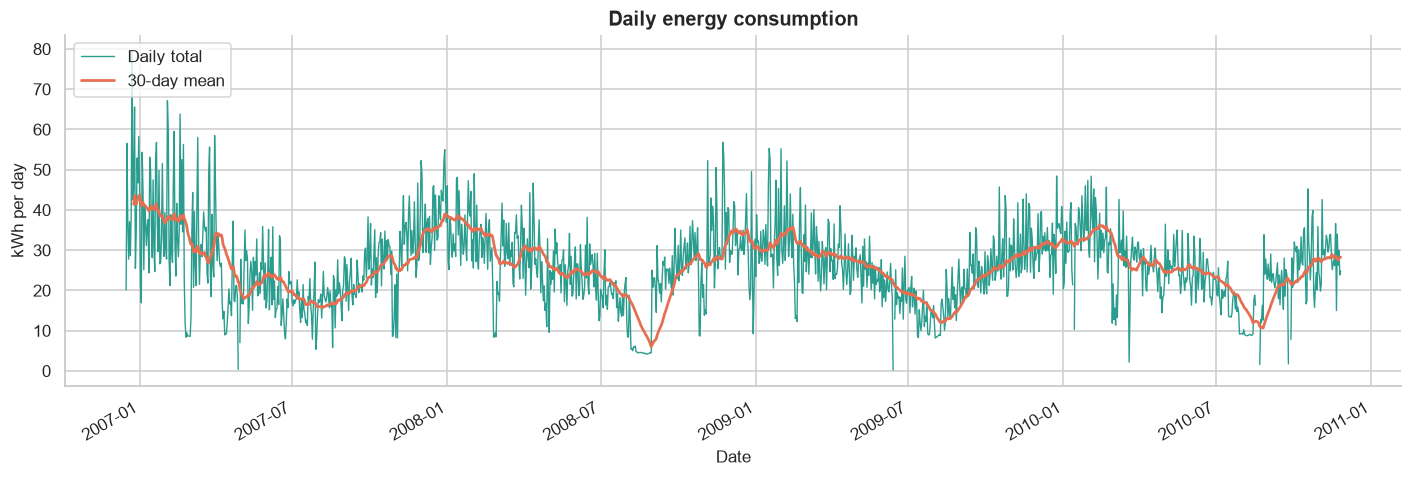

,period_start,valid_observation_count,coverage_percentage,total_energy_consumption_kwh
7,2006-12-23,1440,100.0000,79.5564
49,2007-02-03,1440,100.0000,67.1620
10,2006-12-26,1440,100.0000,65.5685
64,2007-02-18,1440,100.0000,63.8294
50,2007-02-04,1440,100.0000,59.9323


In [14]:
transformed, aggregations, transform_stats = transformer.transform_dataset(
    cleaned,
    grid_start=cleaning_stats.first_timestamp,
    grid_end=cleaning_stats.last_timestamp,
)

energy_summary = pd.DataFrame(
    [
        {"Metric": "Measured valid-reading energy (kWh)", "Value": f"{transform_stats.non_imputed_energy_kwh:,.6f}"},
        {"Metric": "Imputed short-gap energy (kWh)", "Value": f"{transform_stats.imputed_energy_kwh:,.6f}"},
        {"Metric": "Total energy including imputed (kWh)", "Value": f"{transform_stats.total_energy_kwh:,.6f}"},
        {"Metric": "Phase 2 valid-reading total (kWh)", "Value": f"{cleaning_stats.original_valid_energy_kwh:,.6f}"},
        {"Metric": "Sub-metered energy (kWh)", "Value": f"{transform_stats.total_submetering_kwh:,.6f}"},
        {"Metric": "Sub-metered share of total", "Value": f"{transform_stats.submetered_share_percent:.2f}%"},
    ]
)
display(energy_summary)
print(
    "Continuity: measured energy matches Phase 2; the only additional energy "
    "comes from the 76 flagged interpolated minutes."
)

daily = aggregations["daily"]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(
    daily["period_start"],
    daily["total_energy_consumption_kwh"],
    color="#2a9d8f",
    linewidth=0.9,
    label="Daily total",
)
ax.plot(
    daily["period_start"],
    daily["total_energy_consumption_kwh"].rolling(30, min_periods=10).mean(),
    color="#e76f51",
    linewidth=1.8,
    label="30-day mean",
)
ax.set_title("Daily energy consumption")
ax.set_ylabel("kWh per day")
ax.set_xlabel("Date")
ax.legend(loc="upper left")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_daily_energy_trend.png", bbox_inches="tight")
plt.show()

display(
    daily.nlargest(5, "total_energy_consumption_kwh")[
        [
            "period_start",
            "valid_observation_count",
            "coverage_percentage",
            "total_energy_consumption_kwh",
        ]
    ]
)

## 17. Hourly Aggregation

The hourly dataset contains one row for every hour in the full source range,
including hours with no valid measurement. `expected_observation_count` comes
from the complete one-minute grid, so an empty or partial hour cannot hide.

Hourly intervals:       34,589
Incomplete hours:       448
Empty hours:            421
Expected minutes total: 2,075,259
Valid minutes total:    2,049,356


,period_start,expected_observation_count,valid_observation_count,imputed_observation_count,coverage_percentage,is_complete,mean_global_active_power_kw,max_global_active_power_kw,min_global_active_power_kw,total_energy_consumption_kwh,mean_global_reactive_power_kw,mean_voltage_v,mean_global_intensity_a,mean_sub_metering_1_wh,mean_sub_metering_2_wh,mean_sub_metering_3_wh,total_sub_metering_1_kwh,total_sub_metering_2_kwh,total_sub_metering_3_kwh,total_sub_metering_kwh
0,2006-12-16 17:00:00,36,36,0,100.0000,True,4.2229,7.7060,2.4720,2.5337,0.2290,234.6439,18.1000,0.0000,0.5278,16.8611,0.0000,0.0190,0.6070,0.6260
1,2006-12-16 18:00:00,60,60,0,100.0000,True,3.6322,6.7520,2.1880,3.6322,0.0800,234.5802,15.6000,0.0000,6.7167,16.8667,0.0000,0.4030,1.0120,1.4150
2,2006-12-16 19:00:00,60,60,0,100.0000,True,3.4002,4.0700,3.2020,3.4002,0.0852,233.2325,14.5033,0.0000,1.4333,16.6833,0.0000,0.0860,1.0010,1.0870


,period_start,expected_observation_count,valid_observation_count,coverage_percentage,total_energy_consumption_kwh
3175,2007-04-28 00:00:00,60,21,35.0000,0.3790
3176,2007-04-28 01:00:00,60,0,0.0000,NaN
3177,2007-04-28 02:00:00,60,0,0.0000,NaN
3178,2007-04-28 03:00:00,60,0,0.0000,NaN
3179,2007-04-28 04:00:00,60,0,0.0000,NaN


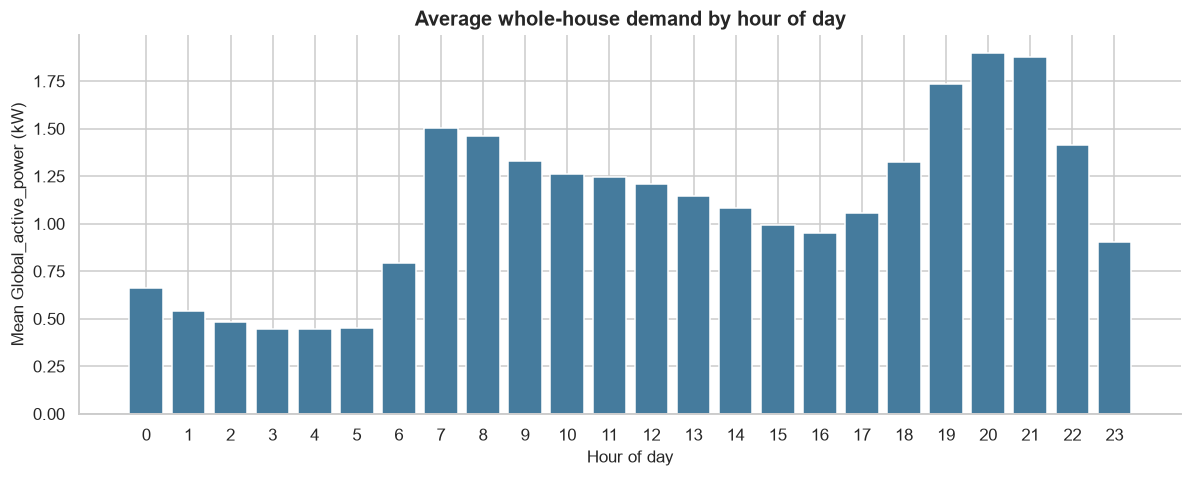

In [15]:
hourly = aggregations["hourly"]
hourly_missing = int((~hourly["is_complete"]).sum())
hourly_empty = int((hourly["valid_observation_count"] == 0).sum())
print(f"Hourly intervals:       {len(hourly):,}")
print(f"Incomplete hours:       {hourly_missing:,}")
print(f"Empty hours:            {hourly_empty:,}")
print(f"Expected minutes total: {int(hourly['expected_observation_count'].sum()):,}")
print(f"Valid minutes total:    {int(hourly['valid_observation_count'].sum()):,}")
display(hourly.head(3))
display(
    hourly.loc[~hourly["is_complete"]].head(5)[
        [
            "period_start",
            "expected_observation_count",
            "valid_observation_count",
            "coverage_percentage",
            "total_energy_consumption_kwh",
        ]
    ]
)

hourly_profile = (
    transformed.groupby("hour", as_index=False)["Global_active_power"].mean()
)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(hourly_profile["hour"], hourly_profile["Global_active_power"], color="#457b9d")
ax.set_title("Average whole-house demand by hour of day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean Global_active_power (kW)")
ax.set_xticks(range(0, 24))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_hourly_profile.png", bbox_inches="tight")
plt.show()

## 18. Daily Aggregation

Daily rows preserve every calendar day from the first to the last timestamp.
Partial days are summed only over their valid minutes and are marked
`is_complete = False`. Nine calendar days have no valid measurement at all and
carry `NaN` energy rather than zero.

Daily intervals:        1,442
Incomplete days:        30
Empty days:             9
Expected minutes total: 2,075,259
Valid minutes total:    2,049,356


,period_start,expected_observation_count,valid_observation_count,imputed_observation_count,coverage_percentage,is_complete,mean_global_active_power_kw,max_global_active_power_kw,min_global_active_power_kw,total_energy_consumption_kwh,mean_global_reactive_power_kw,mean_voltage_v,mean_global_intensity_a,mean_sub_metering_1_wh,mean_sub_metering_2_wh,mean_sub_metering_3_wh,total_sub_metering_1_kwh,total_sub_metering_2_kwh,total_sub_metering_3_kwh,total_sub_metering_kwh
0,2006-12-16,396,396,0,100.0000,True,3.0535,7.7060,0.2840,20.1529,0.0882,236.2438,13.0828,0.0000,1.3788,12.4394,0.0000,0.5460,4.9260,5.4720
1,2006-12-17,1440,1440,0,100.0000,True,2.3545,7.0640,0.2060,56.5077,0.1569,240.0870,9.9990,1.4118,2.9076,9.2646,2.0330,4.1870,13.3410,19.5610
2,2006-12-18,1440,1440,0,100.0000,True,1.5304,6.1580,0.2020,36.7304,0.1124,241.2317,6.4217,0.7382,1.8201,9.7347,1.0630,2.6210,14.0180,17.7020


,period_start,expected_observation_count,valid_observation_count,coverage_percentage,total_energy_consumption_kwh
133,2007-04-28,1440,21,1.4583,0.3790
134,2007-04-29,1440,0,0.0000,NaN
135,2007-04-30,1440,576,40.0000,7.0137
175,2007-06-09,1440,1407,97.7083,17.7346
211,2007-07-15,1440,1310,90.9722,15.2837
228,2007-08-01,1440,1419,98.5417,17.6723
679,2008-10-25,1440,1397,97.0139,25.3859
695,2008-11-10,1440,1434,99.5833,34.8647


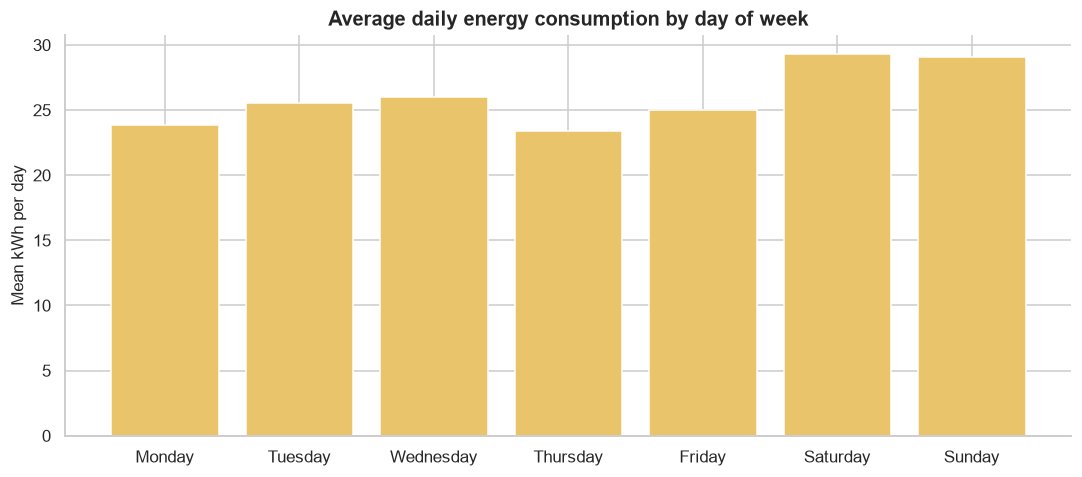

,period_start,total_energy_consumption_kwh,coverage_percentage
7,2006-12-23,79.5564,100.0000
49,2007-02-03,67.1620,100.0000
10,2006-12-26,65.5685,100.0000
64,2007-02-18,63.8294,100.0000
50,2007-02-04,59.9323,100.0000


In [16]:
print(f"Daily intervals:        {len(daily):,}")
print(f"Incomplete days:        {int((~daily['is_complete']).sum()):,}")
print(f"Empty days:             {int((daily['valid_observation_count'] == 0).sum()):,}")
print(f"Expected minutes total: {int(daily['expected_observation_count'].sum()):,}")
print(f"Valid minutes total:    {int(daily['valid_observation_count'].sum()):,}")
display(daily.head(3))
display(
    daily.loc[~daily["is_complete"]].head(8)[
        [
            "period_start",
            "expected_observation_count",
            "valid_observation_count",
            "coverage_percentage",
            "total_energy_consumption_kwh",
        ]
    ]
)

daily_profile = daily.copy()
daily_profile["day_name"] = daily_profile["period_start"].dt.day_name()
weekday_profile = (
    daily_profile.groupby("day_name", as_index=False)["total_energy_consumption_kwh"]
    .mean()
)
weekday_profile["day_name"] = pd.Categorical(
    weekday_profile["day_name"], categories=day_order, ordered=True
)
weekday_profile = weekday_profile.sort_values("day_name")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(
    weekday_profile["day_name"].astype(str),
    weekday_profile["total_energy_consumption_kwh"],
    color="#e9c46a",
)
ax.set_title("Average daily energy consumption by day of week")
ax.set_ylabel("Mean kWh per day")
ax.set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_weekday_energy_profile.png", bbox_inches="tight")
plt.show()

display(
    daily.nlargest(5, "total_energy_consumption_kwh")[
        ["period_start", "total_energy_consumption_kwh", "coverage_percentage"]
    ]
)

## 19. Monthly Aggregation

Monthly rows use month-start labels (`MS`) and preserve every month in the source
range. The first and last months are partial because the dataset starts on
16 December 2006 and ends on 26 November 2010. Long gaps also make some interior
months partial. Energy totals for partial months cover valid minutes only.

Monthly intervals:      48
Incomplete months:      14
Empty months:           0
Expected minutes total: 2,075,259
Valid minutes total:    2,049,356


,period_start,expected_observation_count,valid_observation_count,imputed_observation_count,coverage_percentage,is_complete,total_energy_consumption_kwh
0,2006-12-01,21996,21996,4,100.0000,True,697.1134
1,2007-01-01,44640,44640,2,100.0000,True,"1,150.2883"
2,2007-02-01,40320,40320,2,100.0000,True,941.6138
3,2007-03-01,44640,44640,1,100.0000,True,981.0453
4,2007-04-01,43200,39477,0,91.3819,False,586.3578
5,2007-05-01,44640,44640,0,100.0000,True,733.4812
6,2007-06-01,43200,43167,10,99.9236,False,594.8824
7,2007-07-01,44640,44510,1,99.7088,False,495.0900
8,2007-08-01,44640,44619,1,99.9530,False,568.2793
9,2007-09-01,43200,43200,2,100.0000,True,698.0307


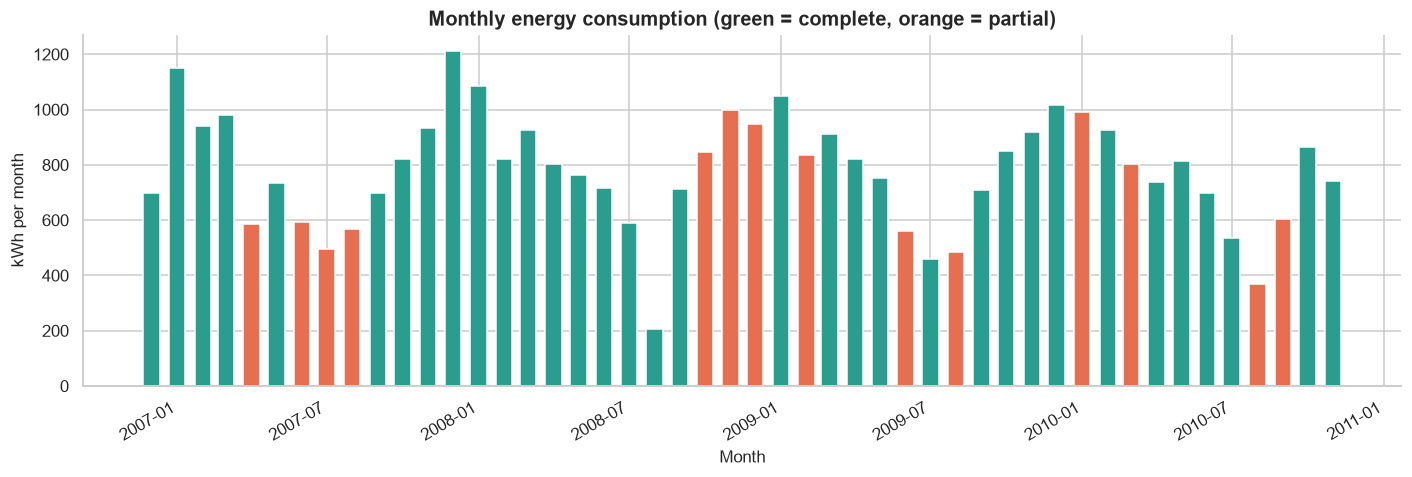

In [17]:
monthly = aggregations["monthly"]
print(f"Monthly intervals:      {len(monthly):,}")
print(f"Incomplete months:      {int((~monthly['is_complete']).sum()):,}")
print(f"Empty months:           {int((monthly['valid_observation_count'] == 0).sum()):,}")
print(f"Expected minutes total: {int(monthly['expected_observation_count'].sum()):,}")
print(f"Valid minutes total:    {int(monthly['valid_observation_count'].sum()):,}")
display(
    monthly[
        [
            "period_start",
            "expected_observation_count",
            "valid_observation_count",
            "imputed_observation_count",
            "coverage_percentage",
            "is_complete",
            "total_energy_consumption_kwh",
        ]
    ]
)

colors = [
    "#2a9d8f" if is_complete else "#e76f51"
    for is_complete in monthly["is_complete"]
]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(
    monthly["period_start"],
    monthly["total_energy_consumption_kwh"],
    width=20,
    color=colors,
)
ax.set_title("Monthly energy consumption (green = complete, orange = partial)")
ax.set_ylabel("kWh per month")
ax.set_xlabel("Month")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "phase3_monthly_energy.png", bbox_inches="tight")
plt.show()

## 20. Validation, Key Findings and Conclusion

Validation combines manual consistency checks, Pandera schemas, cross-aggregate
comparisons and Parquet readback. The full ETL run performs all readback checks;
this notebook reruns the in-memory validation to prove the displayed results are
consistent.

In [18]:
validation = pipeline.validate_outputs(
    transformed,
    aggregations,
    cleaning_stats,
    transform_stats,
    readback=False,
)
validation_summary = pd.DataFrame(
    [
        {"Metric": "Total checks", "Value": f"{len(validation.checks):,}"},
        {"Metric": "Passed checks", "Value": f"{len(validation.passed):,}"},
        {"Metric": "Failed checks", "Value": f"{len(validation.failed):,}"},
        {"Metric": "Warnings", "Value": f"{len(validation.warnings):,}"},
        {"Metric": "Final status", "Value": validation.final_status},
    ]
)
display(validation_summary)

non_pass = pd.DataFrame(
    [
        {"Category": check.category, "Check": check.name, "Status": check.status}
        for check in validation.checks
        if check.status != "PASS"
    ]
)
display(non_pass)
print(f"The {len(validation.warnings)} warnings document data limitations; no validation check failed.")

,Metric,Value
0,Total checks,88
1,Passed checks,82
2,Failed checks,0
3,Warnings,6
4,Final status,PASSED WITH WARNINGS


,Category,Check,Status
0,Data quality,Timestamps are naive local civil time,WARN
1,Data quality,76 rows contain short-gap interpolation,WARN
2,Data quality,"25,903 unresolved rows were removed for modelling",WARN
3,Data quality,IQR outliers were retained,WARN
4,Data quality,"1,050 minutes have sub-metered energy above wh...",WARN
5,Aggregation,Incomplete intervals are present and explicitl...,WARN


The 6 warnings document data limitations; no validation check failed.


In [19]:
assert cleaning_stats.raw_rows == 2_075_259
assert cleaning_stats.original_fully_missing_rows == 25_979
assert cleaning_stats.interpolated_rows == 76
assert cleaning_stats.interpolated_cells == 532
assert cleaning_stats.removed_rows == 25_903
assert cleaning_stats.final_rows == 2_049_356
assert cleaning_stats.final_missing_cells == 0
assert cleaning_stats.outliers_removed == 0
assert len(validation.failed) == 0
assert abs(transform_stats.non_imputed_energy_kwh - 37_283.747700) < 1e-6
assert abs(transform_stats.imputed_energy_kwh - 2.422850) < 1e-6
assert abs(transform_stats.total_energy_kwh - 37_286.170550) < 1e-6

print("All Phase 3 invariants hold.")
print()
print("Generated reports:")
for report_path in sorted(REPORT_DIR.glob("*")):
    if report_path.is_file():
        print(f"  - {report_path.relative_to(PROJECT_ROOT).as_posix()}")
print("Generated notebook figures:")
for figure_path in sorted(FIGURE_DIR.glob("phase3_*.png")):
    print(f"  - {figure_path.relative_to(PROJECT_ROOT).as_posix()}")

All Phase 3 invariants hold.

Generated reports:
  - reports/data-engineering/cleaning_report.txt
  - reports/data-engineering/data_validation_report.txt
  - reports/data-engineering/etl_execution_report.txt
  - reports/data-engineering/missing_values_after_cleaning.csv
  - reports/data-engineering/transformation_report.txt
Generated notebook figures:
  - reports/data-engineering/figures/phase3_daily_energy_trend.png
  - reports/data-engineering/figures/phase3_hourly_profile.png
  - reports/data-engineering/figures/phase3_missing_run_distribution.png
  - reports/data-engineering/figures/phase3_missing_values_by_column.png
  - reports/data-engineering/figures/phase3_monthly_energy.png
  - reports/data-engineering/figures/phase3_outlier_summary.png
  - reports/data-engineering/figures/phase3_record_continuity.png
  - reports/data-engineering/figures/phase3_short_gap_interpolation.png
  - reports/data-engineering/figures/phase3_submetering_check.png
  - reports/data-engineering/figures/ph

### Key Findings

- The raw file contains **2,075,259** rows. Missingness is block-wise: **25,979**
  rows are fully missing across all seven measurements, and there are no partially
  missing rows.
- The missing values form **71 consecutive runs**: **55 short runs / 76 rows**
  qualify for the five-minute interpolation rule, while **16 long runs /
  25,903 rows** remain unresolved.
- Interpolation fills **532 cells** and contributes **2.422850 kWh**. Every
  imputed row is flagged with `is_imputed = True`.
- Unresolved rows are removed only from the final modelling dataset. The result is
  **2,049,356 rows** with **zero missing measurement cells**.
- Measured (non-imputed) energy is **37,283.747700 kWh**, matching the Phase 2
  valid-reading total of **37,283.75 kWh**. Total energy including the flagged
  imputed minutes is **37,286.170550 kWh**.
- **533,669 IQR outlier cells** and **1,050 sub-metering inconsistencies** are
  retained and documented. No consumption peak was deleted, capped, or clipped.
- The aggregates preserve all **2,075,259 expected minutes**. The hourly dataset
  has **34,589 intervals** (448 incomplete, 421 empty), the daily dataset has
  **1,442** (30 incomplete, 9 empty), and the monthly dataset has **48**
  (14 incomplete, 0 empty).
- The full ETL validation reports **90 passed checks, 0 failed checks and
  6 documented warnings**, including the naive-timestamp caveat and the retained
  data-quality issues.

### Conclusion

Phase 3 produces a reproducible, auditable cleaning and transformation layer. The
raw file remains immutable, short gaps are handled transparently, long gaps are
never fabricated, genuine peaks are preserved, and every aggregate exposes its
coverage. The final Parquet datasets and five reports are ready to support later
database, orchestration and modelling phases without pretending that missing
readings are zero consumption.